In [18]:
# from statistics import mode

# import cv2
from keras.models import load_model
from keras import Model
import numpy as np

from utils.datasets import get_labels
from utils.preprocessor import preprocess_input
from utils.datasets import DataManager

# parameters for loading data and images
emotion_model_path = '../trained_models/emotion_models/fer2013_mini_XCEPTION.93-0.64.hdf5'
emotion_labels = get_labels('fer2013')

# hyper-parameters for bounding boxes shape
frame_window = 10
emotion_offsets = (20, 40)
input_shape = (64, 64, 1)

# loading models
base_model = load_model(emotion_model_path, compile=False)
# TODO: is add_4 the correct layer? or is it conv2d_7?
add_4_classifier = Model(inputs=base_model.input, outputs=base_model.get_layer('add_4').output)
conv2d_7_classifier = Model(inputs=base_model.input, outputs=base_model.get_layer('conv2d_7').output)

# getting input model shapes for inference
emotion_target_size = emotion_classifier.input_shape[1:3]

In [19]:
data_loader = DataManager("fer2013", image_size=input_shape[:2])
faces, emotions = data_loader.get_data()
faces = preprocess_input(faces)

/home/ubuntu/Repos/miniXception_vanilla/src/utils/datasets.py:71: FutureWarning: Method .as_matrix will be removed in a future version. Use .values instead.
  emotions = pd.get_dummies(data['emotion']).as_matrix()


In [21]:
embeddings_1 = []
embeddings_2 = []
for face in faces:
    # try:
    #     face = cv2.resize(face, (self._emotion_target_size))
    # except:
    #     continue

    # gray_face = preprocess_input(gray_face, True)
    face = np.expand_dims(face, 0)
    # face = np.expand_dims(face, -1)
    embedding_1 = add_4_classifier.predict(face).flatten()
    embedding_2 = conv2d_7_classifier.predict(face).flatten()
    embeddings_1.append(embedding_1)
    embeddings_2.append(embedding_2)
print(embeddings_1[-1].shape)
print(embeddings_2[-1].shape)
    # print(embedding)

(2048,)
(112,)


Automatically created module for IPython interactive environment


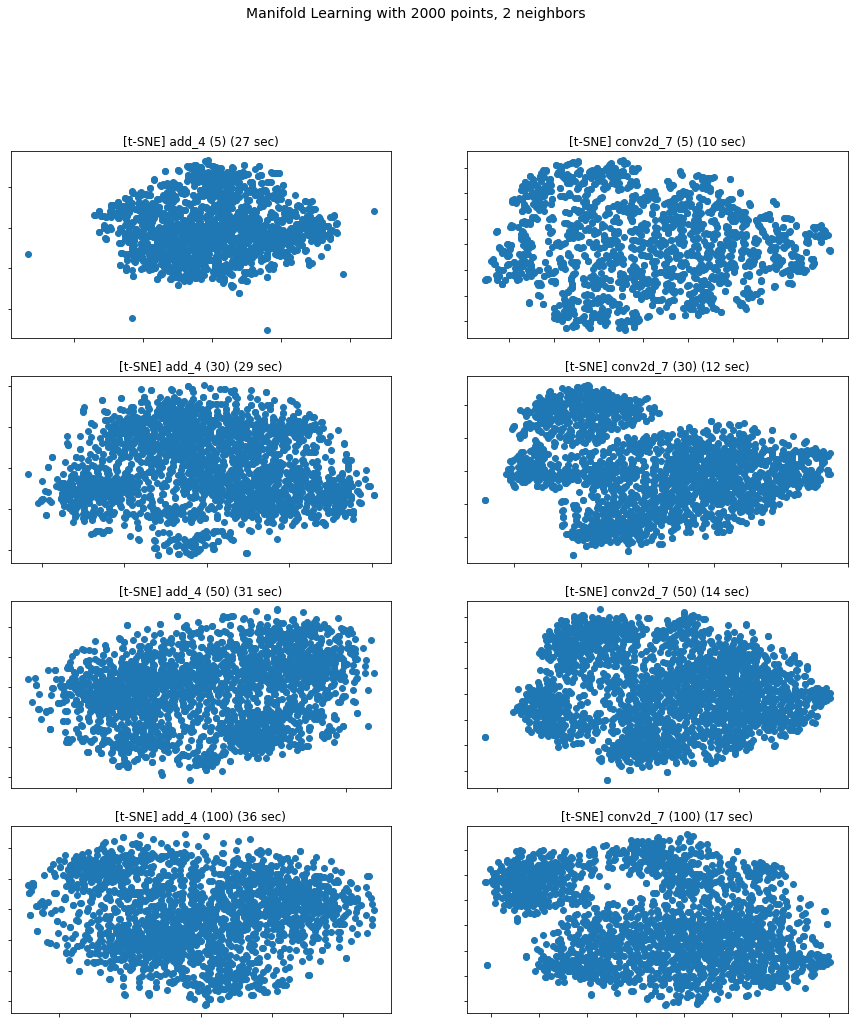

In [29]:
print(__doc__)

from time import time

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.ticker import NullFormatter

from sklearn.manifold import TSNE
from sklearn import datasets

# Next line to silence pyflakes. This import is needed.
Axes3D
n_points = 2000
n_neighbors = 2
n_components = 2

# TODO: set color for 7 expressions
# X, color = datasets.samples_generator.make_s_curve(n_points, random_state=0)
fig = plt.figure(figsize=(15, 20))
plt.suptitle("Manifold Learning with %i points, %i neighbors"
             % (n_points, n_neighbors), fontsize=14)
n_components = 2

# ADD_4 layer embeddings
perplexities = [5, 30, 50, 100]
for i, perplexity in enumerate(perplexities):
    t0 = time()
    tsne = TSNE(n_components=n_components, init='pca', random_state=0, perplexity = perplexity)
    # TODO: Randomize n_points sampled
    Y = tsne.fit_transform(embeddings_1[:n_points])
    t1 = time()
    
    
    ax = fig.add_subplot(5, 2, 2*i+1)
    plt.scatter(Y[:, 0], Y[:, 1], cmap=plt.cm.Spectral)
    plt.title("[t-SNE] add_4 (%d) (%.2g sec)" %  (perplexity, t1 - t0))
    ax.xaxis.set_major_formatter(NullFormatter())
    ax.yaxis.set_major_formatter(NullFormatter())
    plt.axis('tight')


# CONV_2D_7 layer embeddings
for i, perplexity in enumerate(perplexities):
    t0 = time()
    tsne = TSNE(n_components=n_components, init='pca', random_state=0, perplexity = perplexity)
    # TODO: Randomize n_points sampled
    Y = tsne.fit_transform(embeddings_2[:n_points])
    t1 = time()

    ax = fig.add_subplot(5, 2, 2*i+2)
    plt.scatter(Y[:, 0], Y[:, 1], cmap=plt.cm.Spectral)
    plt.title("[t-SNE] conv2d_7 (%d) (%.2g sec)" % (perplexity, t1 - t0))
    ax.xaxis.set_major_formatter(NullFormatter())
    ax.yaxis.set_major_formatter(NullFormatter())
    plt.axis('tight')
    
plt.show()